# Classical Statistical Forecasting with Statsmodels

Compare a constrained AutoReg, ARMA (ARIMA with d=0), ARIMA, and weekly SARIMAX candidate set using training-only diagnostics and intervals.


Chimi & Churri {'AutoReg_AIC': 'TypeError', 'ARMA_AIC': {'aic': np.float64(3831.972172979657), 'bic': np.float64(3856.627658476243)}, 'ARIMA_AIC': {'aic': np.float64(4009.801466726905), 'bic': np.float64(4026.229558277874)}, 'SARIMAX_weekly_AIC': {'aic': np.float64(3654.808256035625), 'bic': np.float64(3675.2534804128595)}}
ARMA_AIC Chimi & Churri       yhat    mean_se  yhat_lower  yhat_upper
date                                                        
2017-03-26      44.959542  16.730213   12.168928   77.750156
2017-03-27      28.298572  16.730234   -4.492083   61.089227
2017-03-28      17.837461  16.730465  -14.953648   50.628570
2017-03-29      21.462663  16.730661  -11.328831   54.254156
2017-03-30      36.440717  16.730663    3.649220   69.232214


residual mean/std: 0.54456105338618 16.900052186231683
ARIMA_AIC Chimi & Churri       yhat    mean_se  yhat_lower  yhat_upper
date                                                        
2017-03-26      50.971043  20.758208   10.285703   91.656383
2017-03-27      32.715088  21.401944   -9.231951   74.662126
2017-03-28      35.711233  21.500628   -6.429223   77.851690
2017-03-29      39.514377  21.533998   -2.691483   81.720236
2017-03-30      39.931167  21.535276   -2.277198   82.139531
residual mean/std: 1.531953000188222 21.03973412061126
SARIMAX_weekly_AIC Chimi & Churri       yhat    mean_se  yhat_lower  yhat_upper
date                                                        
2017-03-26      40.462092  14.824662   11.406289   69.517894
2017-03-27      28.470623  14.836447   -0.608280   57.549525
2017-03-28      26.405818  14.845786   -2.691389   55.503024
2017-03-29      27.533458  14.853188   -1.578255   56.645172
2017-03-30      34.597357  14.859055    5.474145   63.720569


residual mean/std: 0.13041711934418376 15.442510629360187


Assa Frão {'AutoReg_AIC': 'TypeError', 'ARMA_AIC': {'aic': np.float64(4131.067862550703), 'bic': np.float64(4151.614100464524)}, 'ARIMA_AIC': {'aic': np.float64(4119.2866029126235), 'bic': np.float64(4139.821717351335)}, 'SARIMAX_weekly_AIC': {'aic': np.float64(3819.866333444951), 'bic': np.float64(3840.3115578221855)}}
ARMA_AIC Assa Frão        yhat    mean_se  yhat_lower  yhat_upper
date                                                    
2017-03-26  43.558982  23.556621   -2.611148   89.729111
2017-03-27  33.954014  24.579956  -14.221814   82.129842
2017-03-28  33.983280  24.586046  -14.204483   82.171044
2017-03-29  34.012378  24.592064  -14.187181   82.211938
2017-03-30  34.041308  24.598012  -14.169909   82.252525
residual mean/std: -0.9671505076928729 23.63301014383422
ARIMA_AIC Assa Frão        yhat    mean_se  yhat_lower  yhat_upper
date                                                    
2017-03-26  44.075583  23.427926   -1.842309   89.993474
2017-03-27  32.887335  24.397440

residual mean/std: -1.9274023723053013 24.43379737922469
SARIMAX_weekly_AIC Assa Frão        yhat    mean_se  yhat_lower  yhat_upper
date                                                    
2017-03-26  55.534688  17.910044   20.431646   90.637729
2017-03-27  24.976454  18.313848  -10.918029   60.870937
2017-03-28  23.890221  18.486131  -12.341930   60.122372
2017-03-29  19.489216  18.560308  -16.888318   55.866750
2017-03-30  18.274188  18.592366  -18.166180   54.714557
residual mean/std: 0.6643802498972919 20.954641856598812


1200

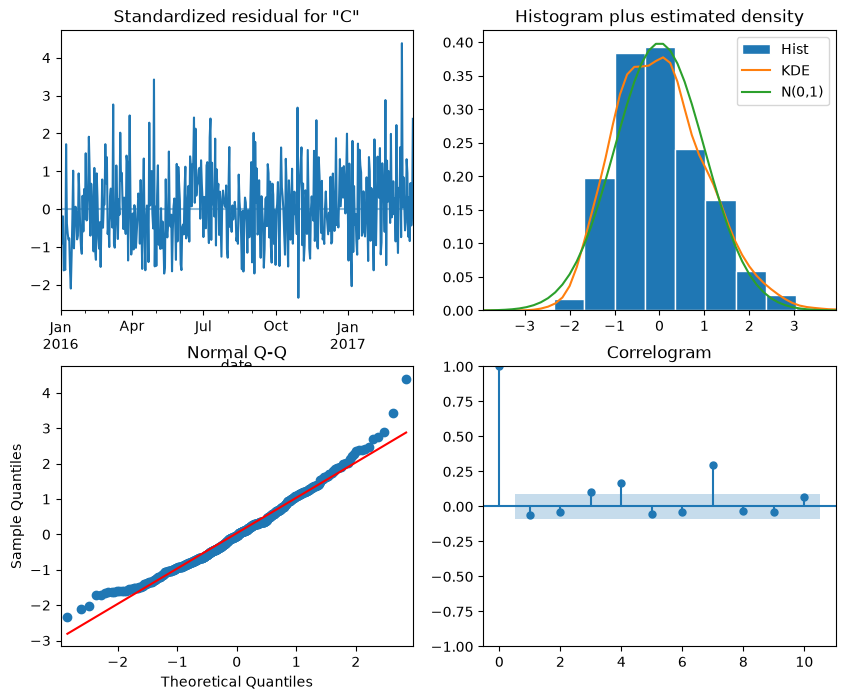

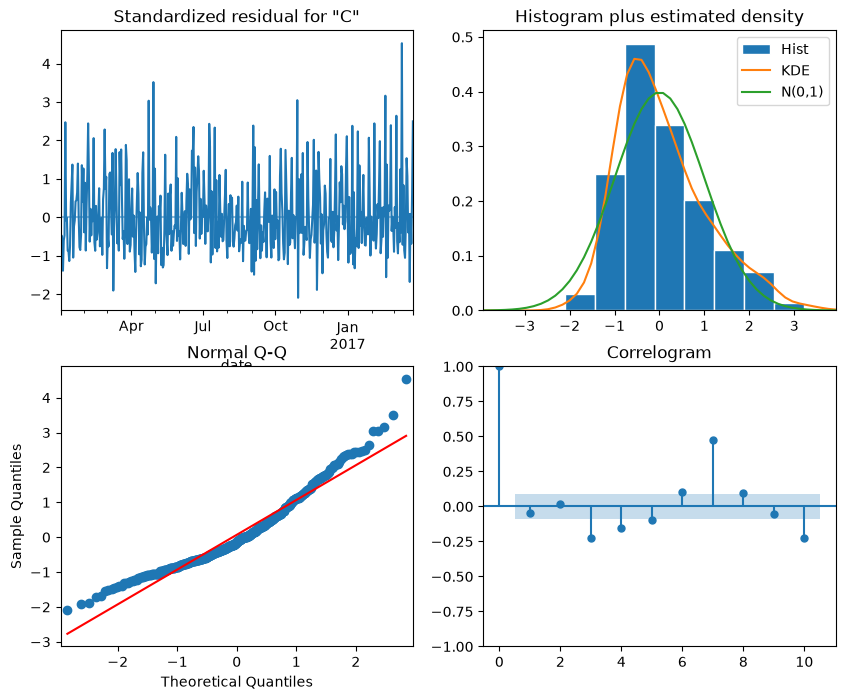

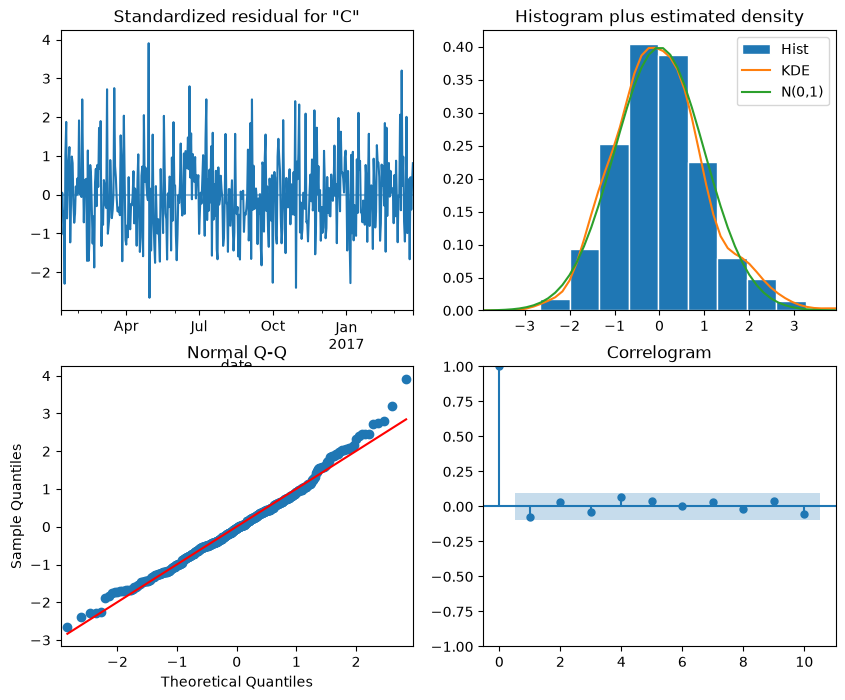

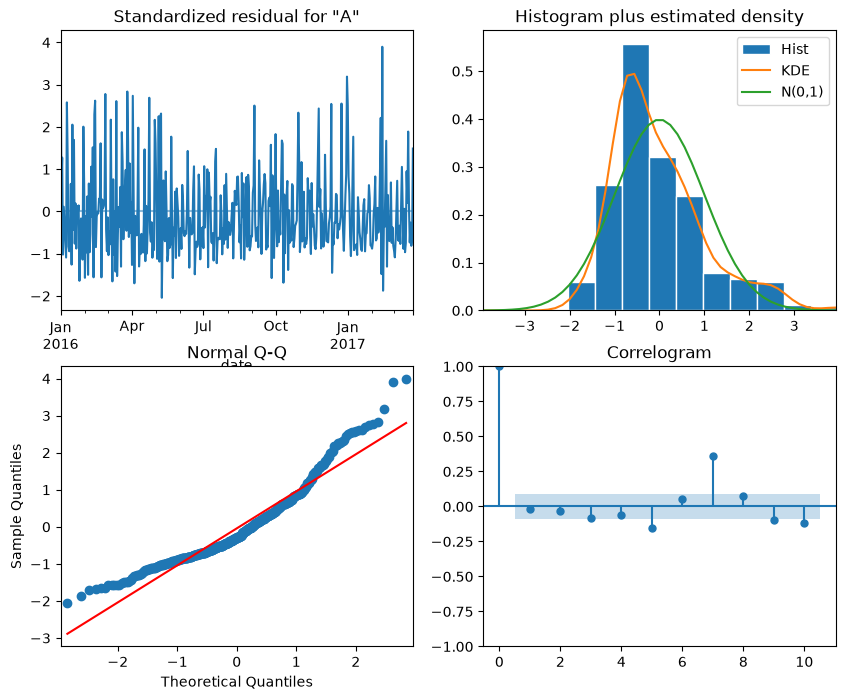

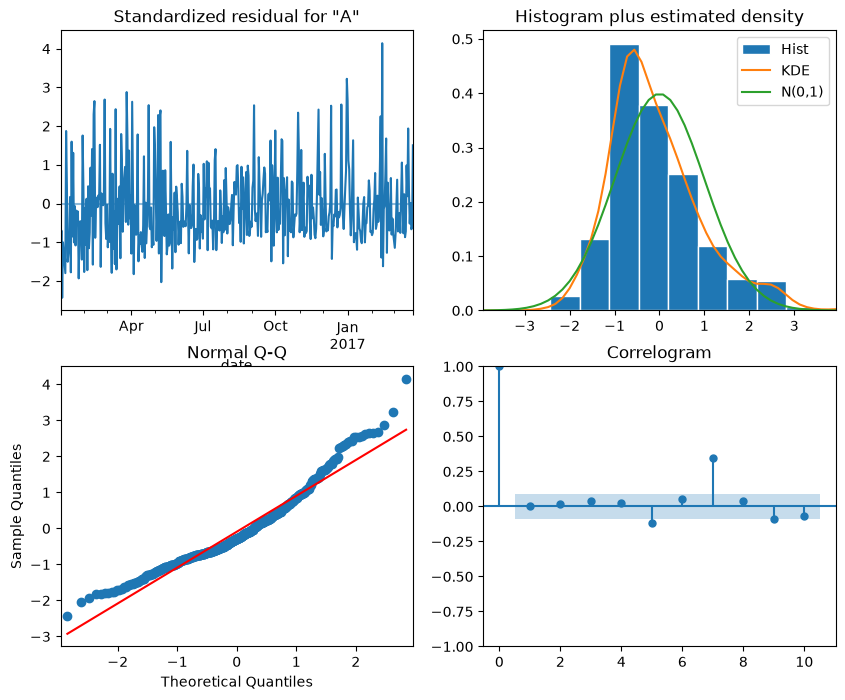

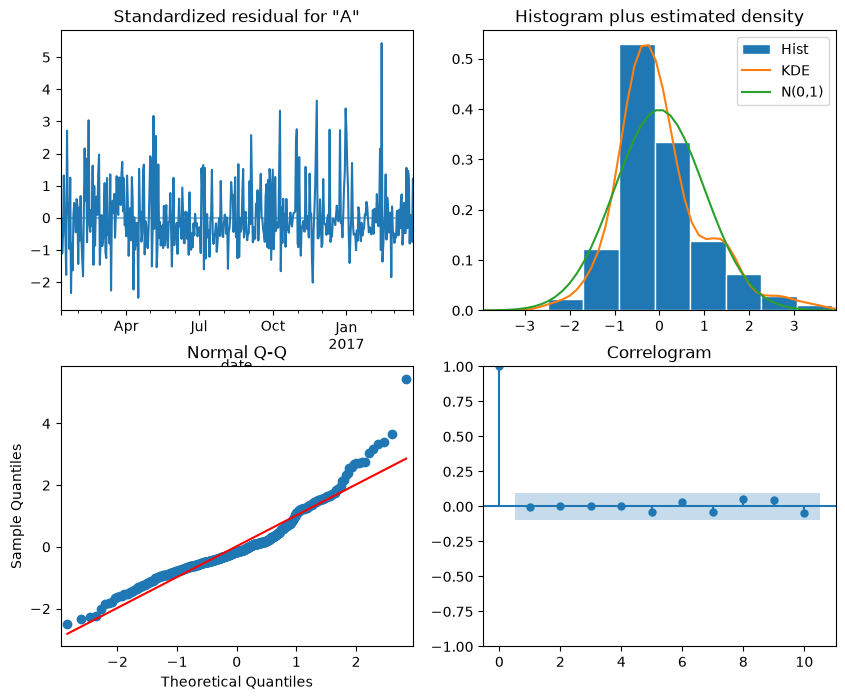

In [1]:
# PROJECT_ROOT_BOOTSTRAP: support kernels started from the repository root or notebooks/.
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Could not locate the project root containing src/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src.data import load_demand, TARGETS
from src.evaluation import chronological_holdout
from src.models.statsmodels_models import fit_candidates, forecast_frame
from pathlib import Path
from importlib.metadata import version
import json
import pandas as pd

demand = load_demand("data/raw/clientes_restaurantes.csv")
forecast_rows = []
metadata_rows = []
for target in TARGETS:
    train, test = chronological_holdout(demand[[target]], 28)
    # Fit the training-only imputation on the training segment; leave test missingness intact.
    train[target] = train[target].interpolate(limit_area="inside")
    train = train.dropna(subset=[target])
    fitted = fit_candidates(train[target])
    print(target, {name: (type(result).__name__ if isinstance(result, Exception) else {"aic": result.aic, "bic": result.bic}) for name, result in fitted.items()})
    for name, result in fitted.items():
        if not isinstance(result, Exception):
            forecast = forecast_frame(result, len(test), test.index)
            print(name, forecast.head())
            metadata_rows.append({"restaurant": target, "model": name, "aic": float(result.aic), "bic": float(result.bic)})
            part = forecast.copy()
            part["restaurant"], part["model"], part["horizon"] = target, name, range(1, len(part)+1)
            part = part.rename_axis("date").reset_index().rename(columns={"yhat": "prediction", "yhat_lower": "lower", "yhat_upper": "upper"})
            forecast_rows.append(part[["date", "restaurant", "model", "horizon", "prediction", "lower", "upper"]])
            result.plot_diagnostics(figsize=(10, 8))
            residuals = result.resid
            print("residual mean/std:", residuals.mean(), residuals.std())
Path("artifacts/forecasts").mkdir(parents=True, exist_ok=True)
pd.concat(forecast_rows).to_csv("artifacts/forecasts/statsmodels_holdout_forecasts.csv", index=False)
metadata = {"training_cutoff": str(demand.index[-29].date()), "package_versions": {"statsmodels": version("statsmodels"), "pandas": version("pandas")}, "parameters": "Constrained training-only AIC order search; weekly seasonal period 7", "validation_method": "chronological 28-calendar-day holdout", "forecast_horizon_days": 28, "fitted_candidates": metadata_rows}
Path("artifacts/models/statsmodels_holdout_metadata.json").write_text(json.dumps(metadata, indent=2))
